# Jawaban Praktikum Kecerdasan Buatan
Soal 1: Eksplorasi Data | Soal 2: Linear Regression | Soal 3: K-NN

> Letakkan file `users_data_cleaned.pickle`, `Sales_Data.csv`, dan `pima-indians-diabetes_data.csv` di folder yang sama dengan notebook ini, lalu jalankan sel dari atas ke bawah. Ambil screenshot code dan output setiap langkah.

# Soal 1: Eksplorasi Data `users_data_cleaned.pickle`

## 1. Load and preview the data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

path = "users_data_cleaned.pickle"
df = pd.read_pickle(path)
df.head()

,user_id,number_transactions,total_amount_usd,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,term_deposit,date_joined,device
0,9231c446-cb16-4b2b-a7f7-ddfc8b25aaf6,3.0,2143.0,58,management,married,tertiary,False,True,False,None,261,1,-1,0,None,False,1998-08-23,mobile
1,bb92765a-08de-4963-b432-496524b39157,NaN,NaN,44,technician,single,secondary,False,True,False,None,151,1,-1,0,None,False,2008-07-15,desktop
2,573de577-49ef-42b9-83da-d3cfb817b5c1,2.0,2.0,33,entrepreneur,married,secondary,False,True,True,None,76,1,-1,0,None,False,2002-06-04,mobile
3,d6b66b9d-7c8f-4257-a682-e136f640b7e3,NaN,NaN,47,blue-collar,married,None,False,True,False,None,92,1,-1,0,None,False,1995-06-29,tablet
4,fade0b20-7594-4d9a-84cd-c02f79b1b526,1.0,1.0,33,None,single,None,False,False,False,None,198,1,-1,0,None,False,1995-08-01,mobile


## 2. Check the shape of the data

In [3]:
print("Jumlah baris dan kolom:", df.shape)

Jumlah baris dan kolom: (45209, 19)


## 3. Check the data types

In [4]:
df.dtypes

user_id                        object
number_transactions           float64
total_amount_usd              float64
age                             int64
job                            object
marital                        object
education                      object
default                          bool
housing                          bool
loan                             bool
contact                        object
duration                        int64
campaign                        int64
pdays                           int64
previous                        int64
poutcome                       object
term_deposit                     bool
date_joined            datetime64[ns]
device                         object
dtype: object

## 4. Check for correlations

In [5]:
df.corr(numeric_only=True)

,number_transactions,total_amount_usd,age,default,housing,loan,duration,campaign,pdays,previous,term_deposit
number_transactions,1.000000,-0.163409,-0.008813,0.138838,0.030429,0.075319,-0.017220,0.026431,-0.030751,-0.023046,-0.053390
total_amount_usd,-0.163409,1.000000,0.095839,-0.065390,-0.066857,-0.084526,0.022586,-0.017274,0.006435,0.016952,0.050785
age,-0.008813,0.095839,1.000000,-0.017875,-0.185552,-0.015641,-0.004645,0.004767,-0.023745,0.001297,0.025168
default,0.138838,-0.065390,-0.017875,1.000000,-0.006020,0.077232,-0.010017,0.016819,-0.029982,-0.018331,-0.022421
housing,0.030429,-0.066857,-0.185552,-0.006020,1.000000,0.041341,0.005041,-0.023583,0.124197,0.037087,-0.139161
loan,0.075319,-0.084526,-0.015641,0.077232,0.041341,1.000000,-0.012395,0.009972,-0.022762,-0.011048,-0.068193
duration,-0.017220,0.022586,-0.004645,-0.010017,0.005041,-0.012395,1.000000,-0.084551,-0.001549,0.001213,0.394549
campaign,0.026431,-0.017274,0.004767,0.016819,-0.023583,0.009972,-0.084551,1.000000,-0.088636,-0.032860,-0.073179
pdays,-0.030751,0.006435,-0.023745,-0.029982,0.124197,-0.022762,-0.001549,-0.088636,1.000000,0.454817,0.103616
previous,-0.023046,0.016952,0.001297,-0.018331,0.037087,-0.011048,0.001213,-0.032860,0.454817,1.000000,0.093232


## 5. Generate summary statistics for numerical data only

In [6]:
df.select_dtypes(include='number').describe()

,number_transactions,total_amount_usd,age,duration,campaign,pdays,previous
count,35210.000000,35210.000000,45209.000000,45209.000000,45209.000000,45209.000000,45209.000000
mean,3.977052,1369.417751,40.935853,258.153067,2.763897,40.199651,0.580349
std,3.814329,3063.412688,10.618653,257.525446,3.098076,100.130586,2.303489
min,1.000000,-8019.000000,18.000000,0.000000,1.000000,-1.000000,0.000000
25%,2.000000,73.000000,33.000000,103.000000,1.000000,-1.000000,0.000000
50%,3.000000,451.000000,39.000000,180.000000,2.000000,-1.000000,0.000000
75%,4.000000,1438.000000,48.000000,319.000000,3.000000,-1.000000,0.000000
max,20.000000,102127.000000,95.000000,4918.000000,63.000000,871.000000,275.000000


## 6. Plot Histograms for all numerical columns

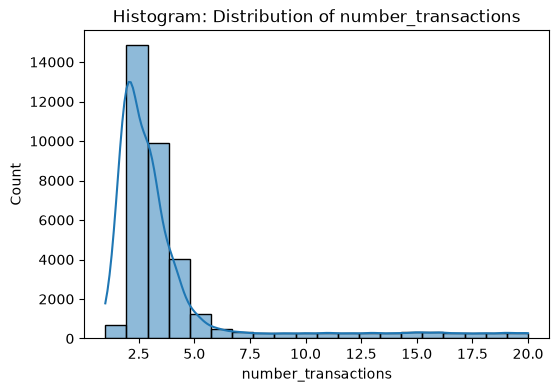

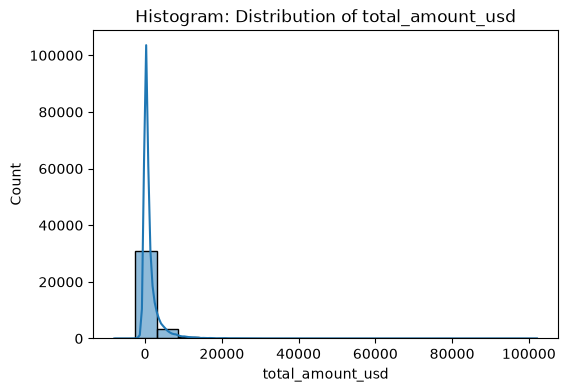

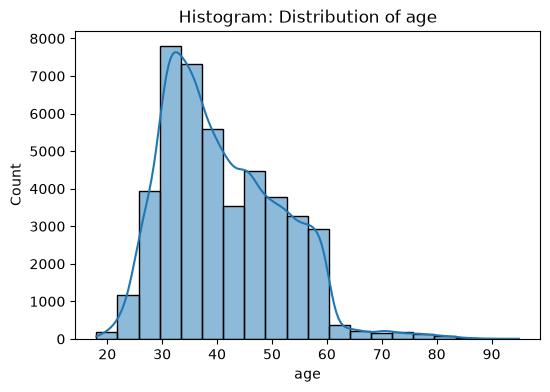

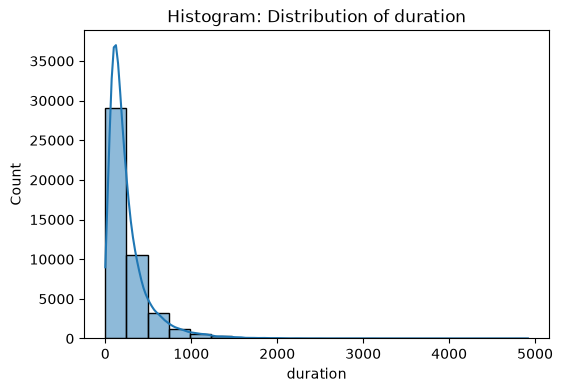

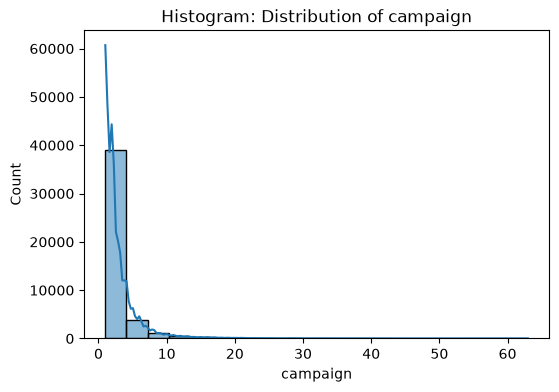

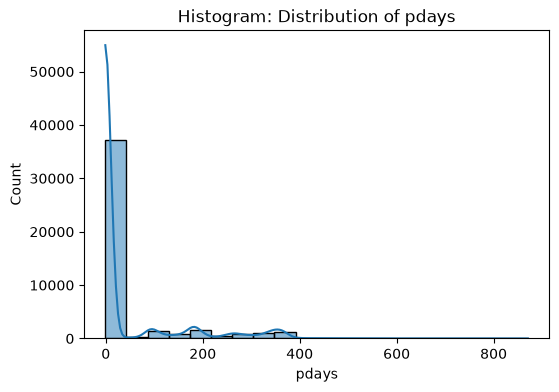

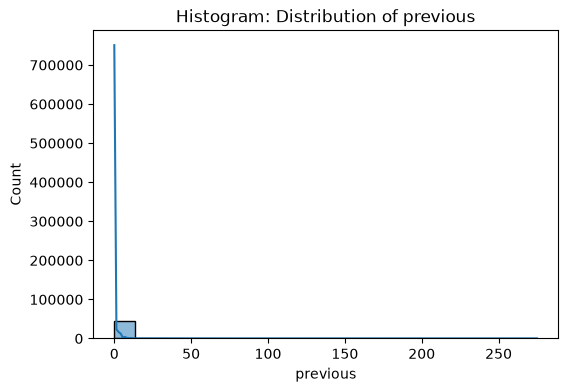

In [7]:
numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], bins=20, kde=True)
    plt.title(f"Histogram: Distribution of {col}")
    plt.show()

## 7. Generate a box plot for *age* and *number_transactions*

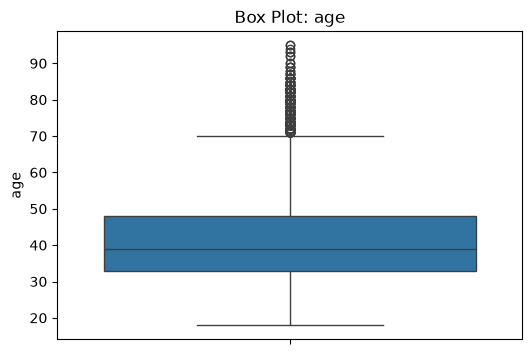

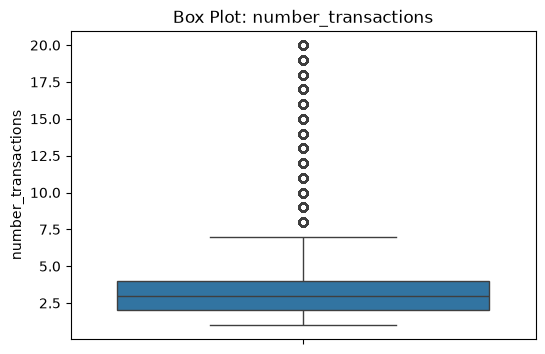

In [8]:
plt.figure(figsize=(6,4))
sns.boxplot(y=df['age'])
plt.title("Box Plot: age")
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(y=df['number_transactions'])
plt.title("Box Plot: number_transactions")
plt.show()

## 8. Generate a lineplot for *date_joined* to *total_amount_usd*

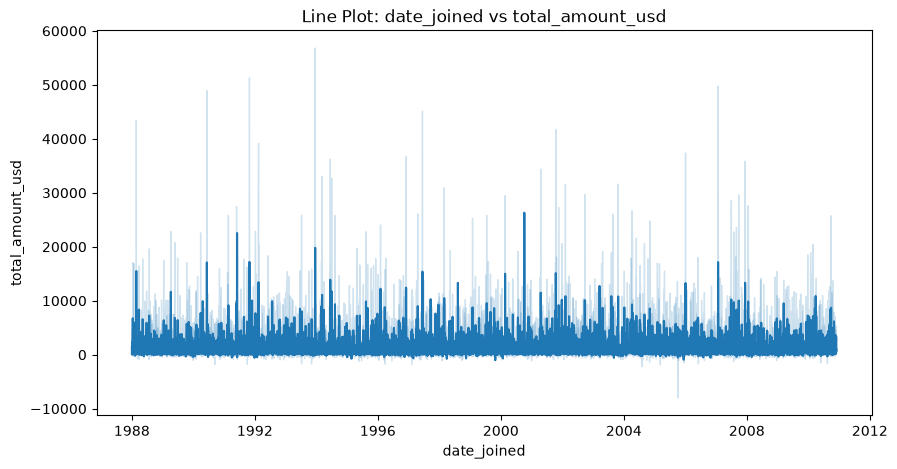

In [9]:
df_sorted = df.sort_values('date_joined')

plt.figure(figsize=(10,5))
sns.lineplot(x='date_joined', y='total_amount_usd', data=df_sorted)
plt.title("Line Plot: date_joined vs total_amount_usd")
plt.xlabel("date_joined")
plt.ylabel("total_amount_usd")
plt.show()

## 9. Generate scatter plots comparing *total_amount_usd* to *number_transaction*

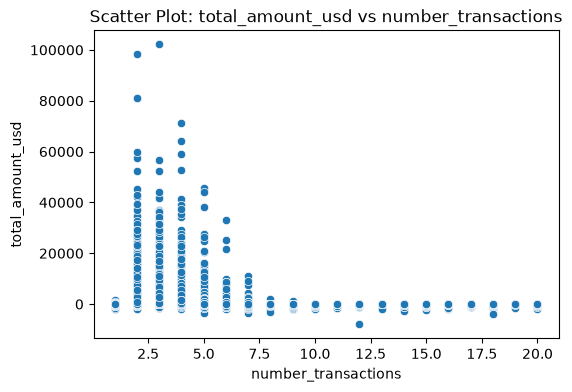

In [10]:
plt.figure(figsize=(6,4))
sns.scatterplot(x='number_transactions', y='total_amount_usd', data=df)
plt.title("Scatter Plot: total_amount_usd vs number_transactions")
plt.show()

## 10. Generate Horizontal bar charts for *job*

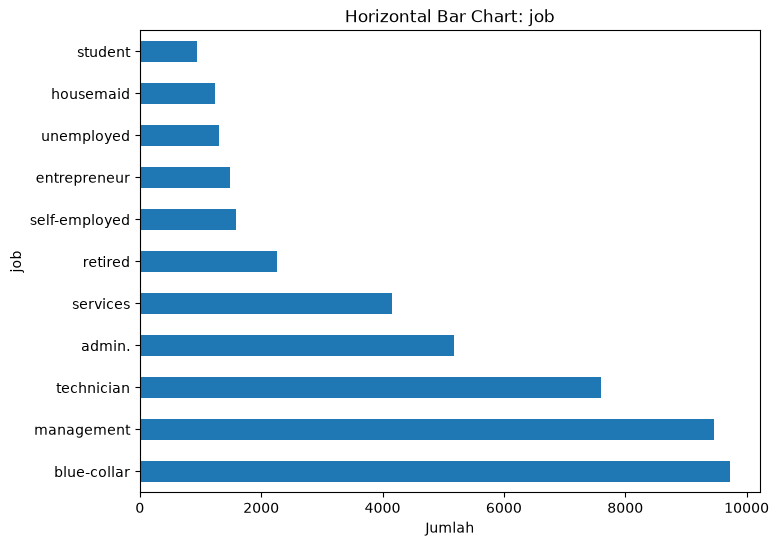

In [11]:
plt.figure(figsize=(8,6))
df['job'].value_counts().plot(kind='barh')
plt.title("Horizontal Bar Chart: job")
plt.xlabel("Jumlah")
plt.ylabel("job")
plt.show()

## 11. Generate Horizontal bar charts for *marital*

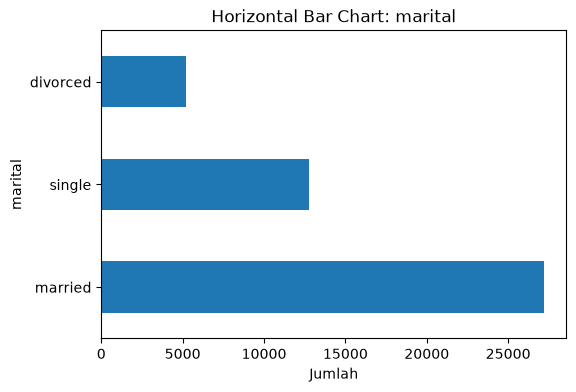

In [12]:
plt.figure(figsize=(6,4))
df['marital'].value_counts().plot(kind='barh')
plt.title("Horizontal Bar Chart: marital")
plt.xlabel("Jumlah")
plt.ylabel("marital")
plt.show()

## 12. Generate a heatmap for feature correlations

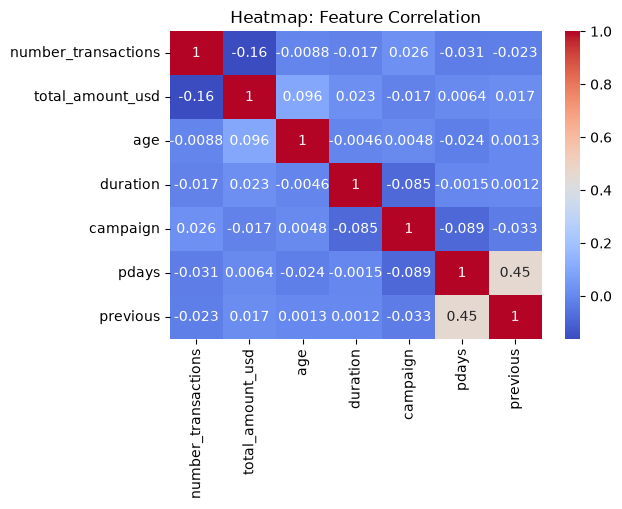

In [13]:
plt.figure(figsize=(6,4))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm')
plt.title("Heatmap: Feature Correlation")
plt.show()

## 13. Identify Missing Values

In [14]:
df.isnull().sum()

user_id                    0
number_transactions     9999
total_amount_usd        9999
age                        0
job                      288
marital                    0
education               1857
default                    0
housing                    0
loan                       0
contact                13018
duration                   0
campaign                   0
pdays                      0
previous                   0
poutcome               36957
term_deposit               0
date_joined               30
device                    94
dtype: int64

In [15]:
percent_missing = 100*df.isnull().mean()
percent_missing

user_id                 0.000000
number_transactions    22.117278
total_amount_usd       22.117278
age                     0.000000
job                     0.637041
marital                 0.000000
education               4.107589
default                 0.000000
housing                 0.000000
loan                    0.000000
contact                28.795151
duration                0.000000
campaign                0.000000
pdays                   0.000000
previous                0.000000
poutcome               81.746997
term_deposit            0.000000
date_joined             0.066358
device                  0.207923
dtype: float64

# Soal 2: Linear Regression `Sales_Data.csv`
Memprediksi **Nilai Penjualan** dari **Biaya Promo**.

## 1.a Membaca file Sales_Data.csv

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('Sales_Data.csv', sep=';')
print(df.head())

   BiayaPromo  NilaiPenjualan
0        1500           90500
1        1800           89500
2        1900          105000
3        2050          102000
4        2050           90500


## 1.b Menampilkan variable dalam dataset
Kolom `BiayaPromo` = X (predictor), kolom `NilaiPenjualan` = y (target).

In [17]:
print("Nama kolom:", list(df.columns))

X = df.iloc[:, :-1].values
y = df.iloc[:, 1].values

print("Variabel X (Biaya Promo), 5 data pertama:\n", X[:5])
print("Variabel y (Nilai Penjualan), 5 data pertama:\n", y[:5])

Nama kolom: ['BiayaPromo', 'NilaiPenjualan']
Variabel X (Biaya Promo), 5 data pertama:
 [[1500]
 [1800]
 [1900]
 [2050]
 [2050]]
Variabel y (Nilai Penjualan), 5 data pertama:
 [ 90500  89500 105000 102000  90500]


## 1.c Menampilkan data yang di-split (train: 80% & test: 20%)

In [18]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

print("X_train:\n", X_train)
print("y_train:\n", y_train)
print("X_test:\n", X_test)
print("y_test:\n", y_test)
print("Jumlah data train:", len(X_train), "| Jumlah data test:", len(X_test))

X_train:
 [[3200]
 [4000]
 [2200]
 [3750]
 [2050]
 [1900]
 [2100]
 [3750]
 [3200]
 [2400]
 [4000]
 [3500]
 [2050]
 [1500]
 [3900]
 [3500]]
y_train:
 [153000 170500 109500 198000  90500 105000 104500 187000 173000 150000
 200500 174500 102000  90500 194500 150000]
X_test:
 [[4100]
 [1800]
 [4500]
 [3050]]
y_test:
 [204500  89500 224500 152000]
Jumlah data train: 16 | Jumlah data test: 4


## 1.d Memanggil LinearRegression()

In [19]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[43.68]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.875e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3395.22]


## 1.e Menampilkan hasil predict dari data test

In [20]:
y_pred = regressor.predict(X_test)
y_pred

array([197842.1437866 ,  97374.89156365, 215314.70939059, 151976.65907612])

## 1.f Menampilkan Grafik Nilai Penjualan berdasarkan Biaya Promosi

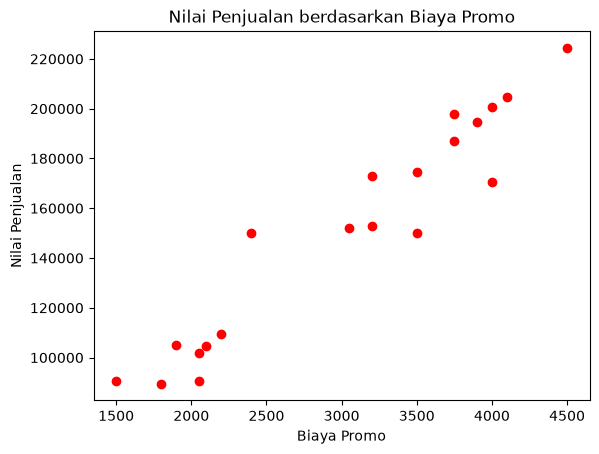

In [21]:
plt.scatter(X, y, color='red')
plt.title('Nilai Penjualan berdasarkan Biaya Promo')
plt.xlabel('Biaya Promo')
plt.ylabel('Nilai Penjualan')
plt.show()

## 1.g Menampilkan garis hasil prediksi pada Biaya Promosi terhadap penjualan (train set dan test set)

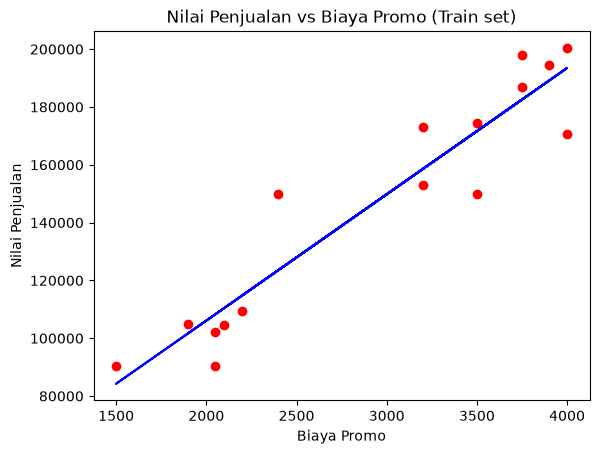

In [22]:
# Train set
plt.scatter(X_train, y_train, color='red')
plt.plot(X_train, regressor.predict(X_train), color='blue')
plt.title('Nilai Penjualan vs Biaya Promo (Train set)')
plt.xlabel('Biaya Promo')
plt.ylabel('Nilai Penjualan')
plt.show()

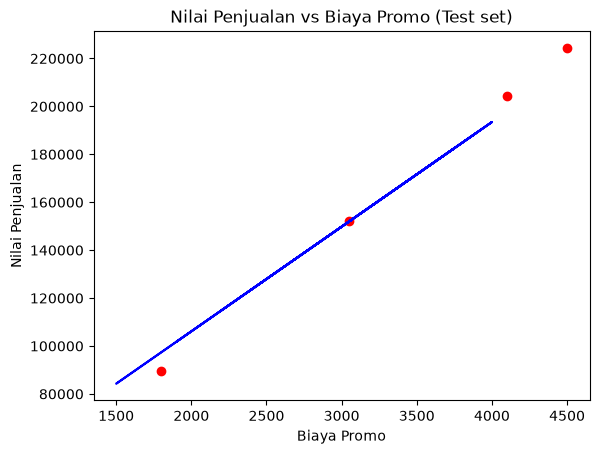

In [23]:
# Test set
plt.scatter(X_test, y_test, color='red')
plt.plot(X_train, regressor.predict(X_train), color='blue')
plt.title('Nilai Penjualan vs Biaya Promo (Test set)')
plt.xlabel('Biaya Promo')
plt.ylabel('Nilai Penjualan')
plt.show()

## 2. Hitunglah Intercept, Slope, dan R-Square

In [24]:
a = regressor.intercept_
b = regressor.coef_[0]

print("a. Estimated model intercept, a:", a)
print("b. Estimated model slope, b:", b)
print(f"   Persamaan: ŷ = {a:.2f} + {b:.2f}x")

a. Estimated model intercept, a: 18748.346345695143
b. Estimated model slope, b: 43.68141400997612
   Persamaan: ŷ = 18748.35 + 43.68x


In [25]:
from sklearn.metrics import r2_score
score = r2_score(y_test, y_pred)
print("c. R-Square:", score)

c. R-Square: 0.9825710284277517


# Soal 3 (NIM Ganjil): K-NN `pima-indians-diabetes.data.csv`
Klasifikasi diabetes (1) atau normal (0).

## 1. Membaca file pima-indians-diabetes.data.csv

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('pima-indians-diabetes_data.csv')
print(df.shape)

(768, 9)


## 2. Menampilkan sebanyak 8 row data teratas

In [26]:
df.head(8)

,preg,glukosa,pres,skin,insulin,BMI,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0


## 3. Menampilkan data features dan label sebanyak 9 row teratas

In [28]:
feature_columns = ['preg', 'glukosa', 'pres', 'skin', 'insulin', 'BMI', 'pedi', 'age']
X = df[feature_columns]
y = df['class']

print("Features (9 row teratas):")
print(X.head(9))
print("\nLabel (9 row teratas):")
print(y.head(9))

Features (9 row teratas):
   preg  glukosa  pres  skin  insulin   BMI   pedi  age
0     6      148    72    35        0  33.6  0.627   50
1     1       85    66    29        0  26.6  0.351   31
2     8      183    64     0        0  23.3  0.672   32
3     1       89    66    23       94  28.1  0.167   21
4     0      137    40    35      168  43.1  2.288   33
5     5      116    74     0        0  25.6  0.201   30
6     3       78    50    32       88  31.0  0.248   26
7    10      115     0     0        0  35.3  0.134   29
8     2      197    70    45      543  30.5  0.158   53

Label (9 row teratas):
0    1
1    0
2    1
3    0
4    1
5    0
6    1
7    0
8    1
Name: class, dtype: int64


## 4. Menampilkan data yang di-split (train: 85% & test: 15%)

In [29]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=0)

print("Jumlah data train:", X_train.shape[0])
print("Jumlah data test :", X_test.shape[0])
print("\nX_train:\n", X_train)
print("\nX_test:\n", X_test)
print("\ny_train:\n", y_train.values)
print("\ny_test:\n", y_test.values)

Jumlah data train: 652
Jumlah data test : 116

X_train:
      preg  glukosa  pres  skin  insulin   BMI   pedi  age
279     2      108    62    10      278  25.3  0.881   22
258     1      193    50    16      375  25.9  0.655   24
249     1      111    86    19        0  30.1  0.143   23
740    11      120    80    37      150  42.3  0.785   48
725     4      112    78    40        0  39.4  0.236   38
..    ...      ...   ...   ...      ...   ...    ...  ...
763    10      101    76    48      180  32.9  0.171   63
192     7      159    66     0        0  30.4  0.383   36
629     4       94    65    22        0  24.7  0.148   21
559    11       85    74     0        0  30.1  0.300   35
684     5      136    82     0        0   0.0  0.640   69

[652 rows x 8 columns]

X_test:
      preg  glukosa  pres  skin  insulin   BMI   pedi  age
661     1      199    76    43        0  42.9  1.394   22
122     2      107    74    30      100  33.6  0.404   23
113     4       76    62     0        0

## 5. Memanggil KNeighborsClassifier dengan n neighbor 5, dengan Euclidean distance

In [30]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn.fit(X_train, y_train)

,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## 6. Hitunglah score akurasinya

In [31]:
y_pred = knn.predict(X_test)
print("Hasil prediksi data test:", y_pred)

result = accuracy_score(y_test, y_pred)
print("Akurasi:", result)

Hasil prediksi data test: [1 0 0 1 0 0 1 1 0 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 1 0 1 1
 0 0 1 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 1 1 1 1 1 1 0 0 0 0 1
 1 0 0 1 0 0 1 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 1 1 0 0 0 1 0
 0 1 0 1 1]
Akurasi: 0.7758620689655172


## 7. Grafik nilai k terhadap akurasi (maks k = 10)

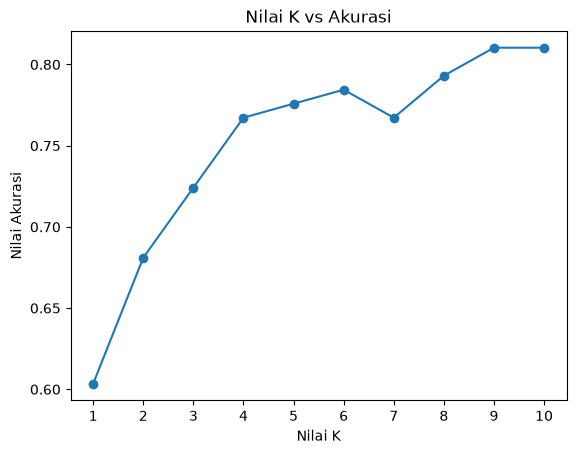

In [32]:
array_k = []
for i in range(1, 11):
    knn = KNeighborsClassifier(n_neighbors=i, metric='euclidean')
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    result = accuracy_score(y_test, y_pred)
    array_k.append(result)

plt.plot(array_k, marker='o')
plt.ylabel('Nilai Akurasi')
plt.xlabel('Nilai K')
plt.xticks(np.arange(10), ('1','2','3','4','5','6','7','8','9','10'))
plt.title('Nilai K vs Akurasi')
plt.show()